# NHANES 2005–2018 — Cycle Distribution & Cohort Selection

This notebook recreates the **Data Description and Characteristics** slides using project-generated, **unweighted** counts. It does not modify source data or rerun the preprocessing pipeline.

**Sources** (produced by your project):
- `outputs/data_analysis/cohort_selection.csv` — stage-wise sample counts by cycle
- `outputs/data_analysis/cycle_statistics.csv` — final sample class distribution by cycle

**Definitions:** adults aged ≥20, complete nine PHQ-9 answers, exclude participants identified as pregnant (`RIDEXPRG == 1`), depression label = PHQ-9 ≥10. Missing pregnancy codes are retained by the original pipeline. These are **sample proportions, not survey-weighted US population prevalence estimates**.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Run from the project root or from data_analysis/ in VS Code.
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "outputs" / "data_analysis" / "cycle_statistics.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find outputs/data_analysis/cycle_statistics.csv. Open the NHANES project root and execute the notebook.")
OUT = ROOT / "outputs" / "data_analysis"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

cycle = pd.read_csv(OUT / "cycle_statistics.csv")
cohort = pd.read_csv(OUT / "cohort_selection.csv")
cycles = ["2005-06", "2007-08", "2009-10", "2011-12", "2013-14", "2015-16", "2017-18"]
cycle = cycle[cycle["cycle"].astype(str).isin(cycles)].copy().set_index("cycle").loc[cycles].reset_index()
cohort = cohort[cohort["cycle"].astype(str).isin(cycles)].copy().set_index("cycle").loc[cycles].reset_index()

assert (cycle["Total"] == cycle["Depression"] + cycle["Non_Depression"]).all()
assert int(cycle["Total"].sum()) == int(cohort["Final_NonPregnant"].sum())
assert (cycle["Total"].to_numpy() == cohort["Final_NonPregnant"].to_numpy()).all()
assert (cohort["All_DEMO"] >= cohort["Age_20_plus"]).all()
assert (cohort["Age_20_plus"] >= cohort["Age_20_plus_Valid_PHQ9"]).all()
assert (cohort["Age_20_plus_Valid_PHQ9"] >= cohort["Final_NonPregnant"]).all()

N = int(cycle["Total"].sum())
P = int(cycle["Depression"].sum())
Q = int(cycle["Non_Depression"].sum())
print(f"Final cohort: {N:,} | Depression: {P:,} ({P/N:.2%}) | Non-depression: {Q:,} ({Q/N:.2%})")
display(cycle)
display(cohort)

Final cohort: 33,498 | Depression: 2,970 (8.87%) | Non-depression: 30,528 (91.13%)


,cycle,Total,Depression,Non_Depression,Depression_Rate
0,2005-06,3975,245,3730,6.16
1,2007-08,5104,498,4606,9.76
2,2009-10,5222,497,4725,9.52
3,2011-12,4594,420,4174,9.14
4,2013-14,4995,482,4513,9.65
5,2015-16,4829,393,4436,8.14
6,2017-18,4779,435,4344,9.10


,cycle,All_DEMO,Age_20_plus,Age_20_plus_Valid_PHQ9,Final_NonPregnant,Excluded_Under20_or_AgeMissing,Excluded_PHQ9_after_age,Excluded_Pregnant_after_PHQ9
0,2005-06,10348,4979,4284,3975,5369,695,309
1,2007-08,10149,5935,5157,5104,4214,778,53
2,2009-10,10537,6218,5281,5222,4319,937,59
3,2011-12,9756,5560,4639,4594,4196,921,45
4,2013-14,10175,5769,5054,4995,4406,715,59
5,2015-16,9971,5719,4888,4829,4252,831,59
6,2017-18,9254,5569,4825,4779,3685,744,46


## Figure 1 — Overall cohort selection

Counts are sequential and obtained from `cohort_selection.csv`. The pregnancy step excludes only participants explicitly identified as pregnant, matching the project code.

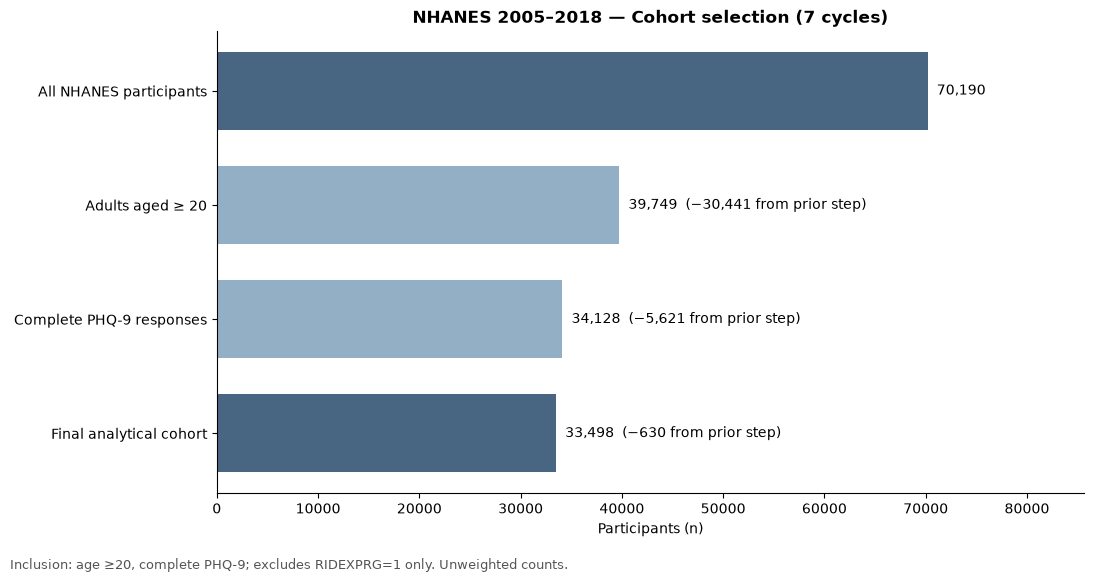

In [2]:
stages = ["All NHANES participants", "Adults aged ≥ 20", "Complete PHQ-9 responses", "Exclude identified pregnant", "Final analytical cohort"]
vals = [int(cohort[k].sum()) for k in ["All_DEMO", "Age_20_plus", "Age_20_plus_Valid_PHQ9", "Final_NonPregnant"]]
assert vals == [70190, 39749, 34128, 33498], "Counts differ from the previously checked cohort; review source files."
fig, ax = plt.subplots(figsize=(11, 5.8))
y = np.arange(len(vals))
ax.barh(y, vals, color=["#486581", "#92afc6", "#92afc6", "#486581"], height=.68)
ax.set_yticks(y, stages[:3] + ["Final analytical cohort"])
ax.invert_yaxis()
ax.set_xlabel("Participants (n)")
ax.set_title("NHANES 2005–2018 — Cohort selection (7 cycles)", weight="bold")
ax.set_xlim(0, max(vals)*1.22)
for i,v in enumerate(vals):
    excluded = f"  (−{vals[i-1]-v:,} from prior step)" if i else ""
    ax.text(v+900, i, f"{v:,}" + excluded, va="center", fontsize=10)
ax.spines[['top','right']].set_visible(False)
fig.text(.01,.01,"Inclusion: age ≥20, complete PHQ-9; excludes RIDEXPRG=1 only. Unweighted counts.",fontsize=9,color="#555555")
fig.tight_layout(rect=[0,.04,1,1])
fig.savefig(FIG / "01_cohort_selection.png", dpi=220, bbox_inches="tight")
plt.show()

## Figure 2 — Overall class distribution

The positive class is `PHQ-9 ≥ 10`. The 8.87% below is **not** a survey-weighted prevalence estimate.

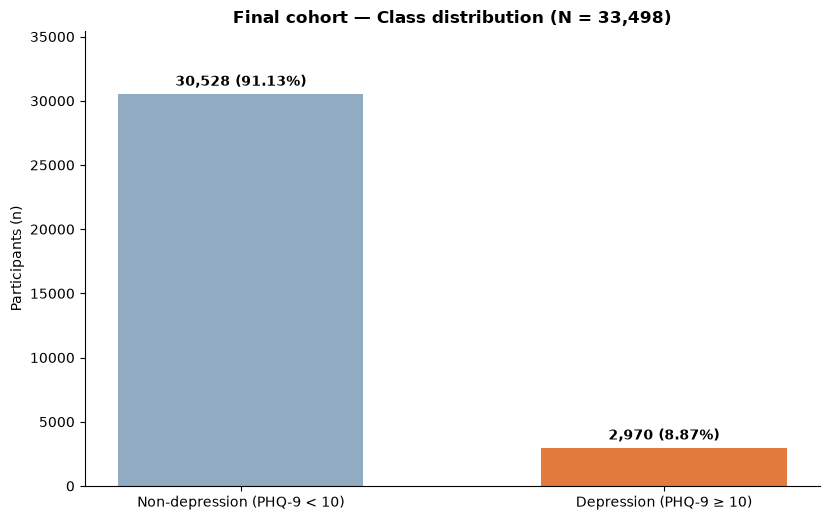

In [3]:
fig, ax = plt.subplots(figsize=(8.4,5.3))
labels = ["Non-depression (PHQ-9 < 10)", "Depression (PHQ-9 ≥ 10)"]
counts = [Q, P]
bars = ax.bar(labels, counts, color=["#91abc3", "#e37a3d"], width=.58)
for bar, count in zip(bars, counts):
    ax.annotate(f"{count:,} ({count/N:.2%})", (bar.get_x()+bar.get_width()/2, count),
                xytext=(0,6),textcoords="offset points",ha="center",fontweight="bold")
ax.set_ylim(0, max(counts)*1.16)
ax.set_ylabel("Participants (n)")
ax.set_title(f"Final cohort — Class distribution (N = {N:,})", weight="bold")
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "02_overall_class_distribution.png", dpi=220, bbox_inches="tight")
plt.show()

## Figure 3 — Class counts by cycle

This graph shows how many negative and positive samples are available in each LOCO test cycle.

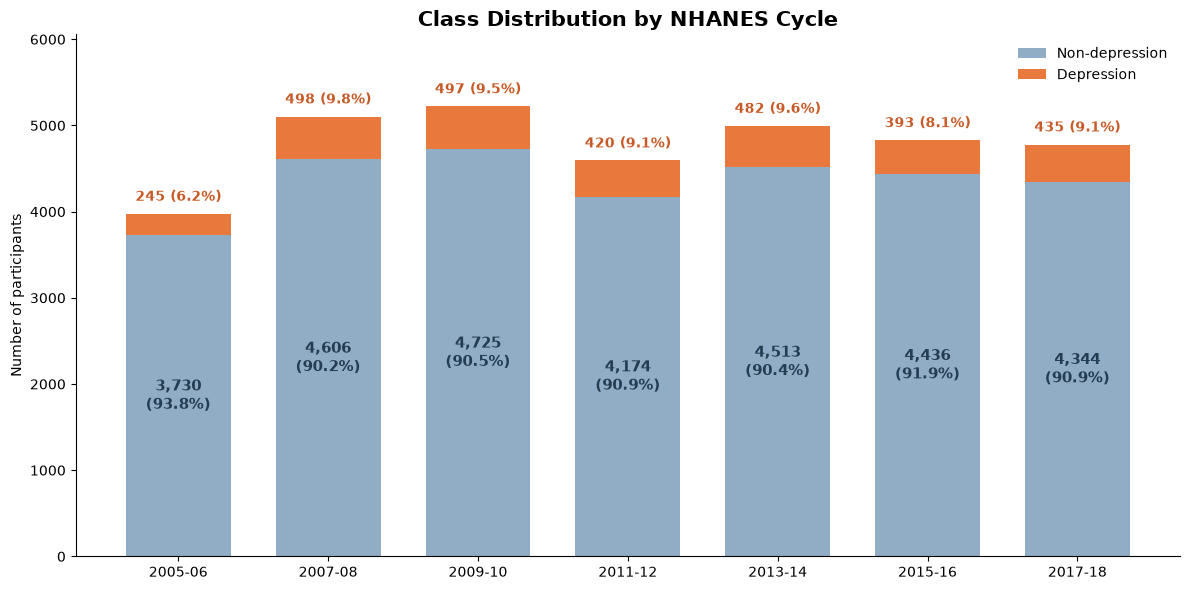

In [7]:

# Class distribution by NHANES cycle
# Show count and percentage for both classes

plot_df = cycle.reset_index()

non_dep = plot_df["Non_Depression"].astype(int).to_numpy()
dep = plot_df["Depression"].astype(int).to_numpy()
total = non_dep + dep

non_dep_pct = non_dep / total * 100
dep_pct = dep / total * 100

x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 6))

# Stacked bar chart
ax.bar(
    x, non_dep,
    color="#91ACC5",
    width=0.7,
    label="Non-depression"
)

ax.bar(
    x, dep,
    bottom=non_dep,
    color="#E9783D",
    width=0.7,
    label="Depression"
)


# Add count and percentage labels
for i in range(len(plot_df)):

    # Non-depression: inside blue bar
    ax.text(
        x[i],
        non_dep[i] / 2,
        f"{non_dep[i]:,}\n({non_dep_pct[i]:.1f}%)",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#243D53"
    )

    # Depression: above stacked bar
    ax.annotate(
        f"{dep[i]:,} ({dep_pct[i]:.1f}%)",
        xy=(x[i], total[i]),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#C75A27",
        annotation_clip=False
    )

ax.set_xticks(x)
ax.set_xticklabels(plot_df["cycle"])

ax.set_ylabel("Number of participants")
ax.set_title(
    "Class Distribution by NHANES Cycle",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylim(0, max(total) * 1.16)
ax.legend(frameon=False, loc="upper right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save figure
fig.savefig(
    FIG / "03_cycle_class_counts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Slide-ready takeaways

- **Data source:** NHANES 2005–2018, seven two-year cycles.
- **Cohort selection:** 70,190 participants → 39,749 aged ≥20 → 34,128 with complete PHQ-9 → **33,498** after excluding identified pregnant participants.
- **Class distribution:** 2,970 positive (8.87%); 30,528 negative (91.13%). This is an **imbalanced classification dataset**.
- **Across-cycle positive rates:** 6.16% (2005–06) to 9.76% (2007–08), calculated **without survey weights**.
- **Evaluation:** the project uses Leave-One-Cycle-Out rather than a single 80/20 train/test split.

All figures are saved in `outputs/data_analysis/figures/`. To reproduce results, run `cycle_statistics.py` and `cohort_selection.py` first, then **Run All** in this notebook.